In [9]:
from __future__ import annotations

import time
from dataclasses import dataclass
from time import perf_counter

import numpy as np
import pandas as pd
from scipy.special import expit
from scipy.stats import beta
from collections import deque
import matplotlib.pyplot as plt
from copy import deepcopy
from time import perf_counter

from typing import List, Dict, Tuple, Optional, Callable

from econml.grf import CausalForest

In [11]:
def fit_offline_causal_forest(
    X_train,
    D_train,
    Y_train,
    X_eval,
    n_trees=500,
    min_leaf=10,
    max_features="sqrt",
    seed=123,
):
    D_train = np.asarray(D_train).astype(float)

    forest = CausalForest(
        n_estimators=n_trees,
        criterion="het",
        min_samples_leaf=min_leaf,
        min_samples_split=2 * min_leaf,
        max_features=max_features,
        max_samples=0.5,
        honest=True,
        fit_intercept=True,
        inference=False,
        n_jobs=-1,
        random_state=seed,
    )

    forest.fit(
        X_train,
        D_train.reshape(-1, 1),
        Y_train,
    )

    tau_hat = forest.predict(X_eval).ravel()
    return tau_hat, forest

# Online Causal Forest

The Online Causal Forest training algorithm is the following:

1. We receive a new datapoint $W_i = (Y_i, D_i, X_i)$
2. The Forest consumes this point and updates summaries and/or splits leafs

## How Forest looks like
The forest consists of $B$ trees $T_b$. Each datapoint is passed to every tree in a forest. The CATE $\tau(x)$ is an average of computed CATEs of each forest:
$$ \tau(x) = \frac{1}{B}\sum_{b=1}^B \tau_b(x). $$

## How each tree splits

Each tree pushes a new observation down to a leaf according to the splits the tree have already made. Every observation becomes either a part of an estimation stream or a structural stream. If its a part of estimation stream, then this observation is used for computation of ATE, otherwise it is used to determine the next split.

Whenever a new leaf is created, we draw a number $m = max(Poisson(\theta) + 1, max_features)$, and then take random $m$ features ${i}$ at which candidate splits will be considered. Then, we create a grid ${c_j}_{j=1}^J$ of a support of each chosen feature. For each pair (i, c) we keep track of summaries $(n_0, n_1, Y_0, Y_1)$, where $n_d$ is a number of observations in a group $d$ and $Y_d$ is a sum of outcomes in a group $d$. In order to determine a split, we wait until the leaf observes at least $n_{struct}$ structural observations and then we split at the $(i, c)$ which yields the maximum heterogeneity between two groups:
$$ (i, c)^* = \text{argmax}_{s = (i, c)} w_L(s)w_R(s)(\tau_L(s) - \tau_R(s))^2, $$
where $w_L(s) = \frac{n_L(s)}{n(s)}$, $n_L(s)$ is the number of observations in a left child, $n_(s)$ is a total number of observations, and $\tau_L(s)$ is an ATE of the left child.

Each leaf's ATE is computed simply as:
$$ \tau(x) = ATE_{current},   $$
where the ATE is using observations from when the split was being decided (from estimation stream) plus the observations that end up in a leaf.

In [12]:
@dataclass
class DataPoint:
    y: float
    d: int
    x: np.ndarray


@dataclass
class DGPSettings:
    d: int # dimension
    e: Callable # propensity function
    m: Callable # prognostic function
    tau: Callable # CATE
    sigma: float # std dev of error term


# constant prop form wager, athey
def wa_e1(x: np.ndarray) -> float:
    return 1/2

# varying prop from wager, athey
def wa_e2(x: np.ndarray) -> float:
    return 1/4 * (1 + beta.pdf(x[0], a=2, b=4))

# constant prog from wa
def wa_m1(x: np.ndarray) -> float:
    return 0.0

# varying prog from wa
def wa_m2(x: np.ndarray) -> float:
    return 2 * x[0] - 1

# varying CATE from wa
def wa_tau1(x: np.ndarray) -> float:
    def zeta(u: float) -> float:
        return 1 + 1/(1 + np.exp(-20 * (u - 1/3)))

    return zeta(x[0]) * zeta(x[1])


class RandomDataStream:
    def __init__(
            self,
            dgp_settings: DGPSettings,
            seed: int = 123,
    ) -> None:
        self.dgp_settings = dgp_settings
        self.seed = seed
        self.rng = np.random.default_rng(seed=self.seed)

    def generate_new_data(self) -> DataPoint:
        n_features = self.dgp_settings.d
        sigma = self.dgp_settings.sigma

        x = self.rng.uniform(0, 1, size=n_features)
        eps = self.rng.normal(loc=0.0, scale=sigma)

        propensity = self.dgp_settings.e(x)
        prognostic = self.dgp_settings.m(x)
        cate = self.dgp_settings.tau(x)

        d = int(self.rng.binomial(n=1, p=propensity))

        y = prognostic + (d - propensity) * cate + eps

        return DataPoint(y=y, d=d, x=x)


In [90]:
class CandidateSummaries:
    def __init__(self, features: np.ndarray, thresholds: np.ndarray) -> None:
        self.features = features
        self.thresholds = thresholds
        self.n_cand = len(self.features)

        shape = (self.n_cand, 2)

        self.n0 = np.zeros(shape, dtype=np.int32)
        self.n1 = np.zeros(shape, dtype=np.int32)
        self.y0 = np.zeros(shape, dtype=np.float64)
        self.y1 = np.zeros(shape, dtype=np.float64)

        self.candidate_idx = np.arange(self.n_cand)

    def update(self, x: np.ndarray, d: int, y: float) -> None:
        sides = (x[self.features] >= self.thresholds).astype(np.int8)

        if d == 1:
            self.n1[self.candidate_idx, sides] += 1
            self.y1[self.candidate_idx, sides] += y
        else:
            self.n0[self.candidate_idx, sides] += 1
            self.y0[self.candidate_idx, sides] += y

    def valid_mask(self, min_arm: int = 1) -> np.ndarray:
        return (
            (self.n0[:, 0] >= min_arm)
            & (self.n1[:, 0] >= min_arm)
            & (self.n0[:, 1] >= min_arm)
            & (self.n1[:, 1] >= min_arm)
        )

    def tau(self) -> np.ndarray:
        tau = np.empty((self.n_cand, 2), dtype=np.float64)

        with np.errstate(divide="ignore", invalid="ignore"):
            tau[:, 0] = self.y1[:, 0] / self.n1[:, 0] - self.y0[:, 0] / self.n0[:, 0]
            tau[:, 1] = self.y1[:, 1] / self.n1[:, 1] - self.y0[:, 1] / self.n0[:, 1]

        return tau

    def split_scores(self, min_arm: int = 1) -> np.ndarray:
        valid = self.valid_mask(min_arm=min_arm)
        tau = self.tau()

        n_left = self.n0[:, 0] + self.n1[:, 0]
        n_right = self.n0[:, 1] + self.n1[:, 1]
        n_total = n_left + n_right

        with np.errstate(divide="ignore", invalid="ignore"):
            w_left = n_left / n_total
            w_right = n_right / n_total
            score = w_left * w_right * (tau[:, 0] - tau[:, 1]) ** 2

        score[~valid] = -np.inf
        return score

    def best_split_index(self, min_arm: int = 1) -> int | None:
        scores = self.split_scores(min_arm=min_arm)

        if np.all(np.isneginf(scores)):
            return None

        return int(np.argmax(scores))

@dataclass(frozen=True)
class SplitLocation:
    feature: int
    threshold: float

    def is_data_point_to_right(self, x: np.ndarray) -> bool:
        return x[self.feature] >= self.threshold


@dataclass(slots=True)
class OnlineSummaries:
    n_0: int = 0
    n_1: int = 0
    y_0: float = 0.0
    y_1: float = 0.0

    def update(self, d: int, y: float) -> None:
        if d == 1:
            self.n_1 += 1
            self.y_1 += y
        else:
            self.n_0 += 1
            self.y_0 += y

    def is_invalid(self, min_arm: int = 1) -> bool:
        return self.n_0 < min_arm or self.n_1 < min_arm

    def get_ate(self) -> float:
        if self.is_invalid():
            raise ValueError("Invalid ATE: missing treatment arm.")
        return self.y_1 / self.n_1 - self.y_0 / self.n_0


class OnlineCausalForest:
    def __init__(
            self,
            n_trees: int,
            theta: float,
            max_feature_split_subset_m: int,
            candidate_grid_size: int,
            c_estim: float,
            alpha_estim: float,
            c_split: float,
            alpha_split: float,
            growth_decay_factor: float,
            share_of_trees_to_mature: float,
            min_arm: int,
            height_threshold: int,
            ghost_branch_size: int,
            ghost_queue_size: int,
            random_seed: int = 123,
    ) -> None:
        self.generations: List[List[CausalTree]] = []
        self.generations_age: List[int] = []
        self.share_of_matured_trees: List[float] = []
        self.n_trees: int = n_trees
        self.theta: float = theta
        self.max_feature_split_subset_m: int = max_feature_split_subset_m
        self.candidate_grid_size: int = candidate_grid_size
        self.c_split: float = c_split
        self.alpha_split: float = alpha_split
        self.alpha_estim: float = alpha_estim
        self.c_estim: float = c_estim
        self.growth_decay_factor: float = growth_decay_factor
        self.share_of_trees_to_mature: float = share_of_trees_to_mature
        self.min_arm: int = min_arm
        self.height_threshold: int = height_threshold
        self.ghost_branch_size: int = ghost_branch_size
        self.ghost_queue_size: int = ghost_queue_size
        self.seed = random_seed
        self.stream: Optional[RandomDataStream] = None

        self.rng = np.random.default_rng(seed=self.seed)

        self._create_new_generation: bool = False

        self.active_trees: int = 0

    def create_new_generation(self) -> None:
        trees = []
        gen_id = len(self.generations)

        for b in range(self.n_trees):
            trees.append(
                CausalTree(
                    forest=self,
                    gen_id=gen_id,
                    random_seed=int(self.rng.integers(0, 2**32 - 1)),
                ).fit(self.stream)
            )

        self.generations.append(trees)
        self.generations_age.append(0)
        self.share_of_matured_trees.append(0.0)

    def fit(self, stream: RandomDataStream) -> 'OnlineCausalForest':
        self.stream = stream
        self.generations = []
        self.generations_age = []
        self.share_of_matured_trees = []
        self._create_new_generation = False
        self.create_new_generation()
        self.active_trees = self.n_trees

        return self

    def consume(self, x: np.ndarray, y: float, d: int) -> None:
        if self.stream is None:
            raise ValueError('Causal Forest has not been fit')

        for gen in self.generations:
            for tree in gen:
                tree.consume(y=y, d=d, x=x)

        if self._create_new_generation:
            self.create_new_generation()
            self._create_new_generation = False

    def compute_ate(self, x: np.ndarray) -> float:
        if self.stream is None:
            raise ValueError('Causal Forest has not been fit')

        num = 0.0
        den = 0.0

        for age, gen in enumerate(reversed(self.generations)):
            w = 1.0

            for tree in gen:
                if (not tree.tree_is_ready) or ((age < len(self.generations) - 1) and tree.height < self.height_threshold):
                    continue

                try:
                    pred = tree.compute_ate(x)
                except ValueError:
                    continue

                num += w * pred
                den += w

        if den == 0:
            raise ValueError("No valid tree prediction yet.")
        return num / den

    def generation_is_mature(self, gen_id: int) -> bool:
        return self.share_of_matured_trees[gen_id] >= self.share_of_trees_to_mature

    def update_height(self, new_height: int, gen_id: int) -> None:
        if new_height % self.height_threshold == 0:
            if gen_id > 0 and new_height // self.height_threshold == 1:
                self.active_trees += 1

            self.share_of_matured_trees[gen_id] += 1 / self.n_trees

        if self.generation_is_mature(gen_id):
            self.generations_age[gen_id] += 1

            if self.generations_age[gen_id] == 1:
                self._create_new_generation = True

            self.share_of_matured_trees[gen_id] = 0


class CausalTree:
    def __init__(
            self,
            forest: OnlineCausalForest,
            gen_id: int,
            random_seed: int = 123,
    ) -> None:
        self.root: Optional[TreeNode] = None
        self.height: int = 0
        self.num_leaves: int = 0
        self.stream: Optional[RandomDataStream] = None
        self.forest = forest
        self.gen_id = gen_id

        self.theta: float = forest.theta
        self.max_feature_split_subset_m: int = forest.max_feature_split_subset_m
        self.min_arm: int = forest.min_arm
        self.candidate_grid_size: int = forest.candidate_grid_size
        self.c_split: float = forest.c_split
        self.alpha_split: float = forest.alpha_split
        self.c_estim: float = forest.c_estim
        self.alpha_estim: float = forest.alpha_estim
        self.ghost_branch_size: int = forest.ghost_branch_size
        self.ghost_queue_size: int = forest.ghost_queue_size

        self.seed = random_seed
        self.rng = np.random.default_rng(seed=self.seed)

        self.tree_is_ready: bool = False

    def fit(self, stream: RandomDataStream) -> 'CausalTree':
        self.stream = stream
        self.root = TreeNode(
            tree=self,
            random_seed=int(self.rng.integers(0, 2**32 - 1)),
        ).fit(stream)
        self.root.ghost_root = True

        self.height = 1
        self.num_leaves = 1

        return self

    def consume(self, x: np.ndarray, y: float, d: int) -> None:
        if self.root is None:
            raise ValueError('Causal Tree has not been fit')

        self.root.consume(y=y, d=d, x=x, estimation=False)

    def compute_ate(self, x: np.ndarray) -> float:
        if self.root is None:
            raise ValueError('Causal Tree has not been fit')

        return self.root.compute_ate(x)

    def update_height(self, new_height: int) -> None:
        if new_height > self.height:
            self.height = new_height

            self.forest.update_height(self.height, self.gen_id)


class TreeNode:
    def __init__(
            self,
            tree: CausalTree,
            parent: Optional[TreeNode] = None,
            is_left_child: Optional[bool] = None,
            random_seed: int = 123,
    ) -> None:
        if parent is None:
            self.depth = 1
        else:
            self.depth = parent.depth + 1

        self.tree = tree
        self.parent: TreeNode = parent
        self.children: List[TreeNode] = []
        self.is_left_child: Optional[bool] = is_left_child
        self.random_seed: int = random_seed
        self.rng = np.random.default_rng(self.random_seed)

        self.split: Optional[SplitLocation] = None

        self.theta: float = tree.theta
        self.max_feature_split_subset_m: int = tree.max_feature_split_subset_m
        self.c_split: float = tree.c_split
        self.alpha_split: float = tree.alpha_split
        self.c_estim: float = tree.c_estim
        self.alpha_estim: float = tree.alpha_estim
        self.min_arm: int = tree.min_arm
        self.candidate_grid_size: int = tree.candidate_grid_size
        self.ghost_branch_size: int = tree.ghost_branch_size
        self.ghost_queue_size: int = tree.ghost_queue_size
        self.n_structure: int = 0

        self.ghost_branches: List[deque[TreeNode]] = [deque([], maxlen=self.ghost_queue_size) for _ in range(2)]

        self.ghost_root: bool = False
        self.ghost_side_promoted: List[bool] = [False, False]
        self.ghost_min_leaf_size: List[deque[int]] = [deque([], maxlen=self.ghost_queue_size) for _ in range(2)]
        self.min_leaf_size: int = 0

        self.structure_candidates: Optional[CandidateSummaries] = None
        self.estimation_summaries: OnlineSummaries = OnlineSummaries()

    def copy(self) -> 'TreeNode':
        node_copy = TreeNode(self.tree, self.parent, self.is_left_child, self.random_seed)
        if len(self.children) > 0:
            node_copy.children = [self.children[0].copy(), self.children[1].copy()]
        else:
            node_copy.children = []
        node_copy.rng = self.rng
        node_copy.split = self.split

        return node_copy

    def convert_to_node(self):
        self.structure_candidates = None
        self.estimation_summaries = None
        self.ghost_branches = None
        self.ghost_side_promoted = None
        self.min_leaf_size = None
        self.ghost_root = False

    def fit(self, stream: RandomDataStream) -> 'TreeNode':
        m = self.rng.poisson(lam=self.theta) + 1
        m = min(m, self.max_feature_split_subset_m, stream.dgp_settings.d)
        m = max(m, 1)
        features: np.ndarray = self.rng.choice(stream.dgp_settings.d, size=m, replace=False)
        grid = np.linspace(0, 1, self.candidate_grid_size + 1)[1:-1]

        candidate_features = np.repeat(features, len(grid))
        candidate_thresholds = np.tile(grid, m)

        self.structure_candidates = CandidateSummaries(candidate_features, candidate_thresholds)
        self.estimation_summaries = OnlineSummaries()

        return self

    def consume(self, x: np.ndarray, d: int, y: float, estimation: bool) -> Optional[int]:
        if self.split is not None:
            side = int(self.split.is_data_point_to_right(x))
            if not self.ghost_root or len(self.ghost_branches[side]) == 0:
                min_leaf = self.children[side].consume(x=x, d=d, y=y, estimation=estimation)

                if min_leaf is not None:
                    self.min_leaf_size = min(self.children[0].min_leaf_size, self.children[1].min_leaf_size)
                    return self.min_leaf_size
            else:
                for i, subtree in enumerate(self.ghost_branches[side]):
                    min_leaf = subtree.consume(x=x, d=d, y=y, estimation=True)
                    if min_leaf is not None:
                        self.ghost_min_leaf_size[side][i] = min_leaf

                self.children[side].consume(x=x, d=d, y=y, estimation=False)
        elif estimation:
            self.estimation_summaries.update(d=d, y=y)
            self.min_leaf_size = min(self.estimation_summaries.n_0, self.estimation_summaries.n_1)

            return self.min_leaf_size
        else:
            self.n_structure += 1
            self.structure_candidates.update(x=x, d=d, y=y)
            self.check_for_split()

    def update_ghosts(self, level: int, is_left_child: bool, starting_depth: int) -> None:
        if self.parent is None or starting_depth < self.ghost_branch_size:
            return

        if level < self.ghost_branch_size:
            if self.parent.ghost_root:
                snapshot = self.copy()

                self.parent.ghost_branches[int(self.is_left_child)].append(snapshot)
                self.parent.ghost_min_leaf_size[int(self.is_left_child)].append(snapshot.min_leaf_size)
            else:
                self.parent.update_ghosts(level + 1, self.is_left_child, starting_depth)
        elif self.parent.ghost_root:
            side = int(self.is_left_child)
            ghosts = self.parent.ghost_branches[side]

            for i, ghost in enumerate(ghosts):
                for ghost_side in range(2):
                    if len(ghost.children) > 0:
                        self.ghost_branches[ghost_side].append(ghost.children[ghost_side])
                        self.ghost_min_leaf_size[ghost_side].append(ghost.children[ghost_side].min_leaf_size)

            self.parent.ghost_branches[side].clear()
            self.parent.ghost_min_leaf_size[side].clear()
            self.parent.ghost_side_promoted[side] = True

            if all(self.parent.ghost_side_promoted):
                self.parent.convert_to_node()
                if (not self.tree.tree_is_ready) and self.parent is self.tree.root:
                    self.tree.tree_is_ready = True

            path_side = int(is_left_child)
            snapshot = self.children[path_side].copy()

            self.ghost_branches[path_side].append(snapshot)
            self.ghost_min_leaf_size[path_side].append(
                snapshot.min_leaf_size
            )
            self.ghost_root = True

    def estimation_ready(self, is_left_child: bool) -> bool:
        if self.parent is None:
            return True

        if self.ghost_root:
            if len(self.ghost_branches[int(is_left_child)]) > 1:
                if self.ghost_min_leaf_size[int(is_left_child)][1] < self.c_estim + self.alpha_estim * self.depth:
                    return False
        else:
            return self.parent.estimation_ready(self.is_left_child)

        return True

    def check_for_split(self) -> None:
        if self.n_structure >= int(self.c_split + self.alpha_split * self.depth) and self.estimation_ready(self.is_left_child):
            self.create_split()

    def create_split(self) -> None:
        k = self.structure_candidates.best_split_index(min_arm=self.min_arm)

        if k is None:
            return

        # # Also require estimation candidate children to be valid
        # if not self.estimation_candidates.valid_mask(min_arm=self.min_arm)[k]:
        #     return

        feature = self.structure_candidates.features[k]
        threshold = self.structure_candidates.thresholds[k]

        self.split = SplitLocation(feature, threshold)

        self.children = [
            TreeNode(
                parent=self,
                tree=self.tree,
                is_left_child=bool(side),
                random_seed=int(self.rng.integers(0, 2**32 - 1)),
            ).fit(self.tree.stream) for side in range(2)
        ]
        self.tree.update_height(self.depth + 1)
        self.update_ghosts(level=1, is_left_child=self.is_left_child, starting_depth=self.depth)

        self.tree.num_leaves += 1

    def compute_ate(self, x: np.ndarray) -> float:
        if self.split is None:
            return self.estimation_summaries.get_ate()
        else:
            side = int(self.split.is_data_point_to_right(x))

            if self.ghost_root and len(self.ghost_branches[side]) > 0:
                return self.ghost_branches[side][0].compute_ate(x)

            return self.children[side].compute_ate(x)



In [172]:
M = 20
epochs = 60
startup_n = 100
n_features = 10

dgp1 = DGPSettings(
    d = n_features,
    sigma = 1,
    e = wa_e1,
    m = wa_m1,
    tau = wa_tau1,
)

mse_mc_online = np.zeros(shape=(epochs, M))
mae_mc_online = np.zeros(shape=(epochs, M))
mse_mc_offline = np.zeros(shape=(epochs, M))
mae_mc_offline = np.zeros(shape=(epochs, M))

In [173]:
rng = np.random.default_rng(1)
large_sample = rng.uniform(0, 1, size=(3000, n_features))
true_cate = [wa_tau1(large_sample[i, :]) for i in range(large_sample.shape[0])]

In [174]:
for m in range(M):
    if (m) % 1 == 0:
        print(f'{m+1}/{M}')

    stream = RandomDataStream(
        dgp_settings=dgp1,
        seed=125 + m + 130,
    )

    forest = OnlineCausalForest(
        n_trees=200,
        ghost_branch_size=1,
        ghost_queue_size=2,
        theta=3,
        max_feature_split_subset_m=5,
        min_arm=5,
        candidate_grid_size=15,
        c_split=20,
        alpha_split=7,
        c_estim=5,
        alpha_estim=5,
        height_threshold=200,
        growth_decay_factor=0.75,
        share_of_trees_to_mature=0.75,
        random_seed=126 + m + 130
    ).fit(stream)

    # mse = []
    # generations = []
    # active_trees = []
    # num_leaves = []
    # height = []

    x_sample = []
    d_sample = []
    y_sample = []

    for i in range(startup_n):
        new_w = stream.generate_new_data()

        forest.consume(y=new_w.y, d=new_w.d, x=new_w.x)
        x_sample.append(new_w.x)
        d_sample.append(new_w.d)
        y_sample.append(new_w.y)

    start = perf_counter()
    for epoch in range(epochs):
        if (epoch) % 5 == 0:
            print(f'epoch: {epoch + 1}/{epochs}. elapsed time: {perf_counter() - start}')

        for i in range(500):
            new_w = stream.generate_new_data()

            forest.consume(y=new_w.y, d=new_w.d, x=new_w.x)
            x_sample.append(new_w.x)
            d_sample.append(new_w.d)
            y_sample.append(new_w.y)

        # generations.append(len(forest.generations))
        # active_trees.append(forest.active_trees)
        # num_leaves.append(np.median([tree.num_leaves for tree in forest.generations[0]]))
        # height.append(np.median([tree.height for tree in forest.generations[0]]))

        offline_forest = fit_offline_causal_forest(
            X_train=np.array(x_sample).reshape(-1, n_features),
            D_train=np.array(d_sample).reshape(-1, 1),
            Y_train=np.array(y_sample).reshape(-1, 1),
            X_eval=large_sample,
            n_trees=200,
            max_features=5,
        )

        # try:
        imse_online = np.mean([(forest.compute_ate(large_sample[i, :]) - true_cate[i]) ** 2 for i in range(large_sample.shape[0])])
        imae_online = np.mean([np.abs(forest.compute_ate(large_sample[i, :]) - true_cate[i]) for i in range(large_sample.shape[0])])
        mse_mc_online[epoch, m] = imse_online
        mae_mc_online[epoch, m] = imae_online

        imse_offline = np.mean([(offline_forest[0][i] - true_cate[i]) ** 2 for i in range(large_sample.shape[0])])
        imae_offline = np.mean([np.abs(offline_forest[0][i] - true_cate[i]) for i in range(large_sample.shape[0])])
        mse_mc_offline[epoch, m] = imse_offline
        mae_mc_offline[epoch, m] = imae_offline
        #mse.append(imse)
        # except ValueError:
        #     print('not ready')
        #     pass


1/20
epoch: 1/60. elapsed time: 3.2499665394425392e-06
epoch: 6/60. elapsed time: 15.687983833951876
epoch: 11/60. elapsed time: 31.669203708996065
epoch: 16/60. elapsed time: 49.84005329199135
epoch: 21/60. elapsed time: 69.84722787496867
epoch: 26/60. elapsed time: 91.88425516698044
epoch: 31/60. elapsed time: 115.7729172919644
epoch: 36/60. elapsed time: 144.9251507499721
epoch: 41/60. elapsed time: 175.3042975839926
epoch: 46/60. elapsed time: 204.57525245897705
epoch: 51/60. elapsed time: 236.22265862498898
epoch: 56/60. elapsed time: 269.2153552089585
2/20
epoch: 1/60. elapsed time: 2.1249870769679546e-06
epoch: 6/60. elapsed time: 15.012073250021785
epoch: 11/60. elapsed time: 31.525169375003316
epoch: 16/60. elapsed time: 50.48854874999961
epoch: 21/60. elapsed time: 71.47720745799597
epoch: 26/60. elapsed time: 94.94595962500898
epoch: 31/60. elapsed time: 120.28432400000747
epoch: 36/60. elapsed time: 147.403647041996
epoch: 41/60. elapsed time: 176.03478858299786
epoch: 46/6

In [160]:
computed_sim[2] = np.c_[mse_mc_online, computed_sim[2]]
computed_sim[0] = np.c_[mse_mc_offline, computed_sim[0]]
computed_sim[1] = np.c_[mae_mc_offline, computed_sim[1]]
computed_sim[3] = np.c_[mae_mc_online, computed_sim[3]]

In [175]:
mse_mc_online = computed_sim[2]
mae_mc_online = computed_sim[3]
mse_mc_offline = computed_sim[0]
mae_mc_offline = computed_sim[1]

In [176]:
computed_sim = [mse_mc_offline.copy(), mae_mc_offline.copy(), mse_mc_online.copy(), mae_mc_online.copy()]

In [163]:
import joblib

joblib.dump(computed_sim, 'sim_causal_forest.pkl')

['sim_causal_forest.pkl']

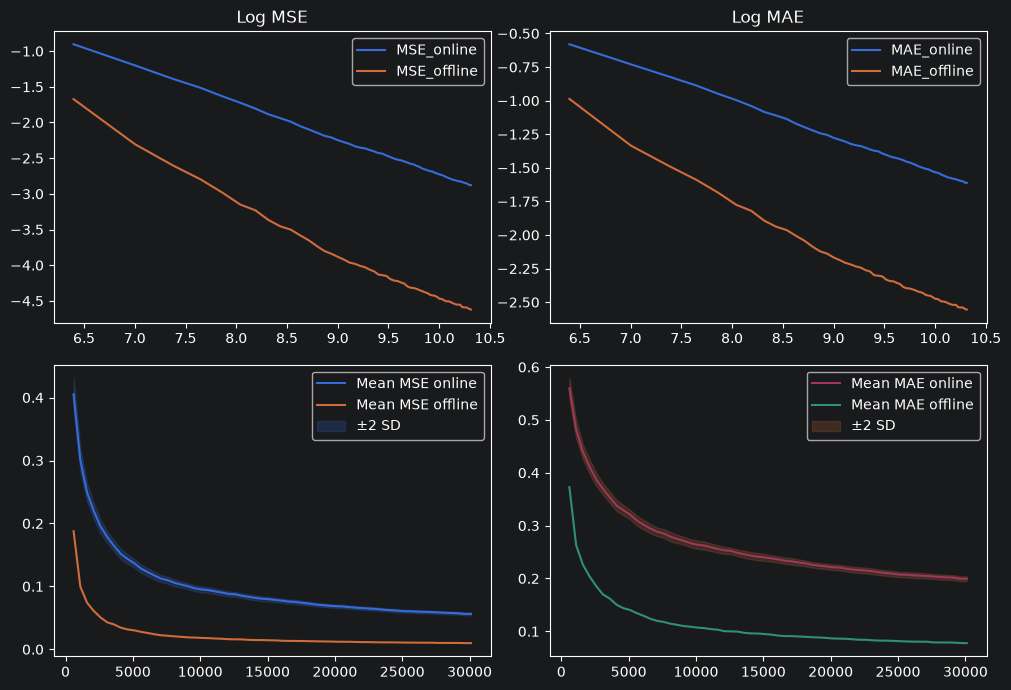

In [164]:
mean_mse_online = np.mean(mse_mc_online, axis=1)
std_mse_online = np.std(mse_mc_online, axis=1)
mean_mae_online = np.mean(mae_mc_online, axis=1)
std_mae_online = np.std(mae_mc_online, axis=1)
mean_mse_offline = np.mean(mse_mc_offline, axis=1)
std_mse_offline = np.std(mse_mc_offline, axis=1)
mean_mae_offline = np.mean(mae_mc_offline, axis=1)
std_mae_offline = np.std(mae_mc_offline, axis=1)

n = startup_n + 500 * np.arange(1, epochs + 1)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes[0, 0].plot(np.log(n), np.log(mean_mse_online), label="MSE_online")
axes[0, 0].plot(np.log(n), np.log(mean_mse_offline), label="MSE_offline")
axes[0, 0].set_title("Log MSE")
axes[0, 0].legend()

axes[0, 1].plot(np.log(n), np.log(mean_mae_online), label="MAE_online")
axes[0, 1].plot(np.log(n), np.log(mean_mae_offline), label="MAE_offline")
axes[0, 1].set_title("Log MAE")
axes[0, 1].legend()

# Level plots with ±2 SD bands
axes[1, 0].plot(n, mean_mse_online, color="C0", label="Mean MSE online")
axes[1, 0].plot(n, mean_mse_offline, color="C1", label="Mean MSE offline")
axes[1, 0].fill_between(
    n,
    mean_mse_online - 2 * std_mse_online / np.sqrt(std_mse_online.shape[0]),
    mean_mse_online + 2 * std_mse_online / np.sqrt(std_mse_online.shape[0]),
    color="C0",
    alpha=0.2,
    label=r"$\pm 2$ SD",
)
axes[1, 0].legend()

axes[1, 1].plot(n, mean_mae_online, color="C2", label="Mean MAE online")
axes[1, 1].plot(n, mean_mae_offline, color="C3", label="Mean MAE offline")
axes[1, 1].fill_between(
    n,
    mean_mae_online - 2 * std_mae_online / np.sqrt(std_mse_online.shape[0]),
    mean_mae_online + 2 * std_mae_online / np.sqrt(std_mse_online.shape[0]),
    color="C1",
    alpha=0.2,
    label=r"$\pm 2$ SD",
)
axes[1, 1].legend()

fig.tight_layout()
plt.show()

In [168]:
import statsmodels.api as sm

sm.OLS(exog=sm.add_constant(np.log(np.arange(startup_n + 500 * 30, startup_n + 500 * (epochs + 1), 500))), endog=np.log(mean_mse_offline[29:])).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.996
Model:                            OLS   Adj. R-squared:                  0.996
Method:                 Least Squares   F-statistic:                     6890.
Date:                Sun, 02 Aug 2026   Prob (F-statistic):           4.92e-36
Time:                        13:22:36   Log-Likelihood:                 109.29
No. Observations:                  31   AIC:                            -214.6
Df Residuals:                      29   BIC:                            -211.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.9347      0.065     14.379      0.000       0.802       1.068
x1            -0.5392      0.006    -83.004      0.000      -0.552      -0.526
==============================================================================
Omnibus:                        0.342   Durbin-Watson:                   1.463
Prob(Omnibus):                  0.843   Jarque-Bera (JB):                0.508
Skew:                           0.059   Prob(JB):                        0.776
Kurtosis:                       2.384   Cond. No.                         497.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [46]:
import statsmodels.api as sm

sm.OLS(exog=sm.add_constant(np.log(np.arange(startup_n + 50, startup_n + 50 * (epochs + 1), 50))), endog=np.log(mean_mae_offline)).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.983
Model:                            OLS   Adj. R-squared:                  0.983
Method:                 Least Squares   F-statistic:                     5673.
Date:                Sat, 01 Aug 2026   Prob (F-statistic):           1.50e-88
Time:                        21:57:03   Log-Likelihood:                 169.88
No. Observations:                 100   AIC:                            -335.8
Df Residuals:                      98   BIC:                            -330.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.7058      0.047     36.050      0.000       1.612       1.800
x1            -0.4606      0.006    -75.320      0.000      -0.473      -0.448
==============================================================================
Omnibus:                       67.568   Durbin-Watson:                   0.296
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              445.256
Skew:                           2.098   Prob(JB):                     2.06e-97
Kurtosis:                      12.447   Cond. No.                         83.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""